# Phase 2 – Audio Quality Analysis and Visualisation
**Gujarati Accent Classifier**

Goal: understand the acoustic properties and recording quality of the 28 standardised recordings *before* MFCC extraction.

**Scope and caveats (read first)**
- Purely descriptive and exploratory. No audio is modified, trimmed, denoised or normalised; the figures show the Phase 1 WAVs as they are.
- There is **one speaker per accent**, so every difference seen here is confounded with speaker identity, microphone/device, recording environment, file codec, and the vocabulary each speaker chose. Nothing below is evidence about the accent of a whole region.
- With 4 speakers and 28 files, no significance tests are run.
- Surti is pending; it appears in tables as 0 recordings and will be included automatically once Phase 1 has processed it.

## 1. Imports and paths
The project config and Phase 1 metadata are reused; analysis helpers are in `src/audio_analysis.py`. Figures go to `results/audio_analysis/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dataset").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import config as cfg
import audio_analysis as aa

OUT = aa.RESULTS_DIR
OUT.mkdir(parents=True, exist_ok=True)
ACCENTS = [a.accent for a in cfg.ACCENTS]
# Consistent colour per accent across every figure (colour-blind-safe Okabe-Ito)
COLORS = {"Ahmedabad": "#0072B2", "Kutchi": "#E69F00", "Mehsani": "#009E73",
          "Kathiyawadi": "#CC79A7", "Surti": "#999999"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.width", 220, "display.max_columns", 40)

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")
    print("saved:", (OUT / name).relative_to(PROJECT_ROOT).as_posix())

## 2. Section A – Dataset overview
Load `dataset/recordings_metadata.csv` and verify it. `recording_type` is intentionally empty (not known) so it is not counted as missing metadata.

In [2]:
meta = pd.read_csv(cfg.METADATA_CSV)
print("Total recordings:", len(meta))
display(meta.groupby("accent").size().reindex(ACCENTS, fill_value=0).rename("recordings").to_frame())

# --- metadata integrity checks ---
required = [c for c in meta.columns if c != "recording_type"]
missing = meta[required].isna().sum()
print("Missing values in required columns:", int(missing.sum()))
print("Status values:", meta["conversion_status"].value_counts().to_dict())
print("Sample rates:", sorted(meta["sample_rate"].unique()), "| Channels:", sorted(meta["channels"].unique()),
      "| Subtypes:", sorted(meta["audio_subtype"].unique()))
print("Duplicate recording IDs:", int(meta["recording_id"].duplicated().sum()))
print("Processed files missing on disk:",
      [p for p in meta["processed_file_path"] if not (cfg.PROJECT_ROOT / p).is_file()])
assert (meta["sample_rate"] == cfg.TARGET_SAMPLE_RATE).all() and (meta["channels"] == cfg.TARGET_CHANNELS).all()
assert (meta["audio_subtype"] == cfg.TARGET_SUBTYPE).all() and (meta["duration_seconds"] > 0).all()
print("Format verification passed: all files are 16 kHz / mono / PCM_16 with positive duration.")

Total recordings: 28


,recordings
accent,
Ahmedabad,7
Kutchi,7
Mehsani,7
Kathiyawadi,7
Surti,0


Missing values in required columns: 0
Status values: {'success': 28}
Sample rates: [np.int64(16000)] | Channels: [np.int64(1)] | Subtypes: ['PCM_16']
Duplicate recording IDs: 0
Processed files missing on disk: []
Format verification passed: all files are 16 kHz / mono / PCM_16 with positive duration.


In [3]:
display(meta[["recording_id", "speaker_id", "accent", "original_format", "duration_seconds"]]
        .sort_values(["accent", "recording_id"]).reset_index(drop=True))

dur = (meta.groupby("accent")["duration_seconds"].agg(n="count", min="min", max="max", mean="mean", median="median", std="std")
       .reindex(ACCENTS).round(2))
display(dur)
dur.to_csv(OUT / "duration_summary_by_accent.csv")

,recording_id,speaker_id,accent,original_format,duration_seconds
0,AHM_S01_R01,AHM_S01,Ahmedabad,M4A,14.187
1,AHM_S01_R02,AHM_S01,Ahmedabad,M4A,11.968
2,AHM_S01_R03,AHM_S01,Ahmedabad,M4A,11.989
3,AHM_S01_R04,AHM_S01,Ahmedabad,M4A,12.160
4,AHM_S01_R05,AHM_S01,Ahmedabad,M4A,17.259
5,AHM_S01_R06,AHM_S01,Ahmedabad,M4A,12.117
6,AHM_S01_R07,AHM_S01,Ahmedabad,M4A,16.448
7,KAT_S01_R01,KAT_S01,Kathiyawadi,OGG,10.614
8,KAT_S01_R02,KAT_S01,Kathiyawadi,OGG,9.594
9,KAT_S01_R03,KAT_S01,Kathiyawadi,OGG,9.873


,n,min,max,mean,median,std
accent,,,,,,
Ahmedabad,7.0,11.97,17.26,13.73,12.16,2.28
Kutchi,7.0,13.76,16.96,15.08,15.15,1.01
Mehsani,7.0,10.81,18.25,14.20,14.25,2.85
Kathiyawadi,7.0,9.59,15.19,11.43,10.87,1.89
Surti,NaN,NaN,NaN,NaN,NaN,NaN


**Duration charts.** Left: mean duration per accent with every individual recording overlaid. Right: distribution (boxplots with 7 points each are only a rough guide to spread).

saved: results/audio_analysis/01_duration_bar_by_accent.png


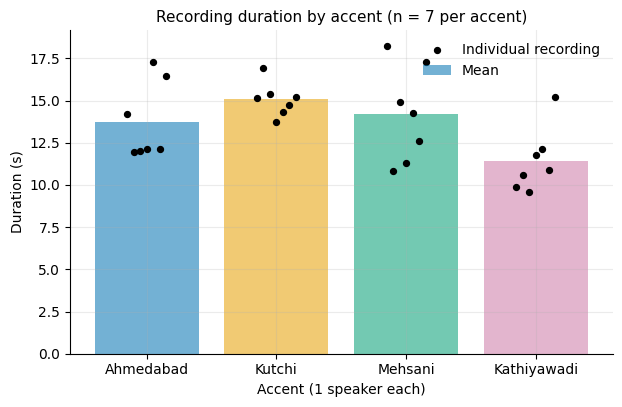

saved: results/audio_analysis/02_duration_boxplot.png


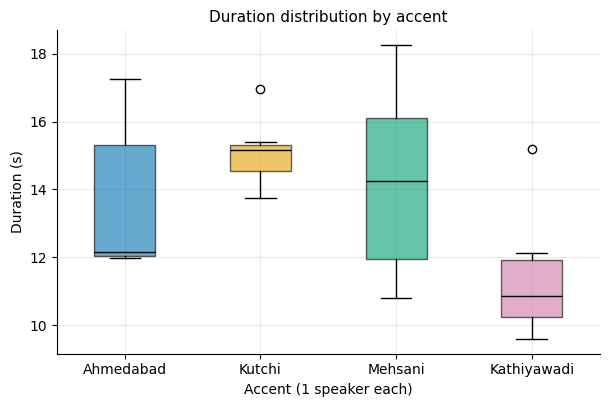

In [4]:
present = [a for a in ACCENTS if a in set(meta["accent"])]
fig, ax = plt.subplots(figsize=(7, 4.2))
means = [meta.loc[meta.accent == a, "duration_seconds"].mean() for a in present]
ax.bar(present, means, color=[COLORS[a] for a in present], alpha=0.55, label="Mean")
for i, a in enumerate(present):
    v = meta.loc[meta.accent == a, "duration_seconds"]
    ax.scatter(np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), v, color="black", s=18, zorder=3,
               label="Individual recording" if i == 0 else None)
ax.set_ylabel("Duration (s)"); ax.set_xlabel("Accent (1 speaker each)")
ax.set_title("Recording duration by accent (n = 7 per accent)"); ax.legend(frameon=False)
save(fig, "01_duration_bar_by_accent.png"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2))
bp = ax.boxplot([meta.loc[meta.accent == a, "duration_seconds"] for a in present], tick_labels=present,
                patch_artist=True, medianprops={"color": "black"})
for patch, a in zip(bp["boxes"], present):
    patch.set_facecolor(COLORS[a]); patch.set_alpha(0.6)
ax.set_ylabel("Duration (s)"); ax.set_xlabel("Accent (1 speaker each)")
ax.set_title("Duration distribution by accent")
save(fig, "02_duration_boxplot.png"); plt.show()

## 3. Per-recording analysis (feeds Sections D and E)
Each WAV is loaded with `librosa.load(sr=None)` (no resampling) and analysed read-only:

- **Frame energy**: RMS in 25 ms frames, 10 ms hop, in dB.
- **Activity classes** are defined *relative to each file's own loud-speech level* (99th-percentile frame level, `ref`), so differences in recording gain do not shift the result:
  - **speech-level**: frame ≥ ref − 30 dB
  - **quiet / low-energy**: between ref − 45 dB and ref − 30 dB (could be soft speech, breaths, word endings or room noise)
  - **silence**: < ref − 45 dB
- Leading/trailing silence = time before the first / after the last speech-level frame. **Internal pause** = a gap of ≥ 200 ms between speech-level frames. Speech bursts < 50 ms are ignored.
- "Low-energy frames %" = quiet + silence (everything not speech-level).

This is an energy method, not a trained VAD: energy alone cannot reliably tell quiet speech from low noise, which is why the quiet class is reported separately rather than called silence.

In [5]:
records, activities = [], {}
for _, r in meta.iterrows():
    stats, act = aa.analyse_recording(cfg.PROJECT_ROOT / r["processed_file_path"])
    records.append({"recording_id": r["recording_id"], "accent": r["accent"], "speaker_id": r["speaker_id"],
                    "original_format": r["original_format"], **stats})
    activities[r["recording_id"]] = act
analysis = aa.add_quality_flags(pd.DataFrame(records))
analysis.round(3).to_csv(OUT / "audio_quality_metrics.csv", index=False)
print("Analysed", len(analysis), "recordings. Metrics saved to results/audio_analysis/audio_quality_metrics.csv")

reps = aa.representative_recordings(meta)
print("Representative recordings (duration closest to each accent's median):")
display(reps[["accent", "recording_id", "duration_seconds"]].reset_index(drop=True))
REP = {row["accent"]: row for _, row in reps.iterrows()}
def rep_audio(accent):
    row = REP[accent]
    y, sr = aa.load_audio(cfg.PROJECT_ROOT / row["processed_file_path"])
    return row["recording_id"], y, sr

C:\Users\91966\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Analysed 28 recordings. Metrics saved to results/audio_analysis/audio_quality_metrics.csv
Representative recordings (duration closest to each accent's median):


,accent,recording_id,duration_seconds
0,Ahmedabad,AHM_S01_R04,12.160
1,Kutchi,KUT_S01_R01,15.147
2,Mehsani,MEH_S01_R05,14.254
3,Kathiyawadi,KAT_S01_R06,10.873


## 4. Section B – Waveforms
Waveforms of the representative recording per accent (amplitude on the file's native scale, −1 to 1; no normalisation). All panels share the same amplitude axis, and the comparison figure also shares the time axis, so visual loudness and length are directly comparable.

saved: results/audio_analysis/03_waveform_Ahmedabad_AHM_S01_R04.png


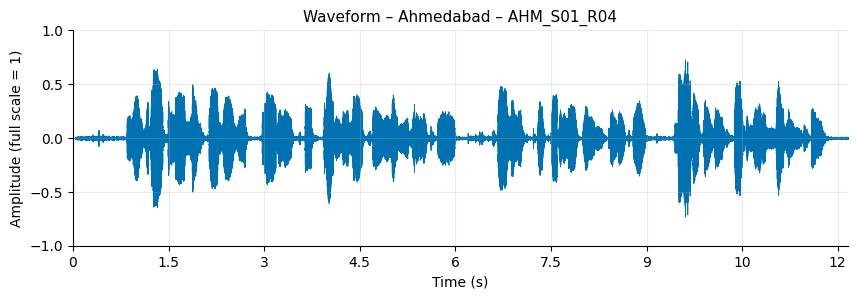

saved: results/audio_analysis/03_waveform_Kutchi_KUT_S01_R01.png


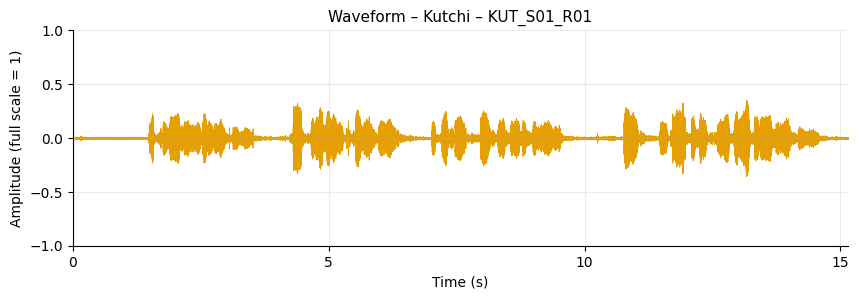

saved: results/audio_analysis/03_waveform_Mehsani_MEH_S01_R05.png


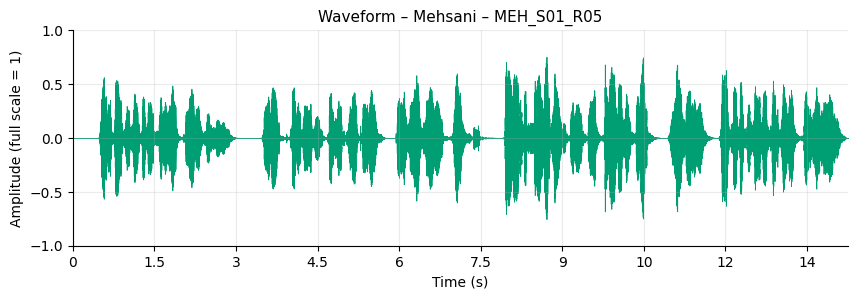

saved: results/audio_analysis/03_waveform_Kathiyawadi_KAT_S01_R06.png


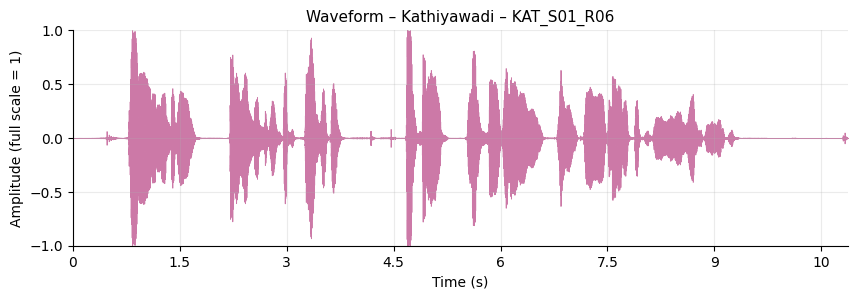

saved: results/audio_analysis/04_waveform_comparison.png


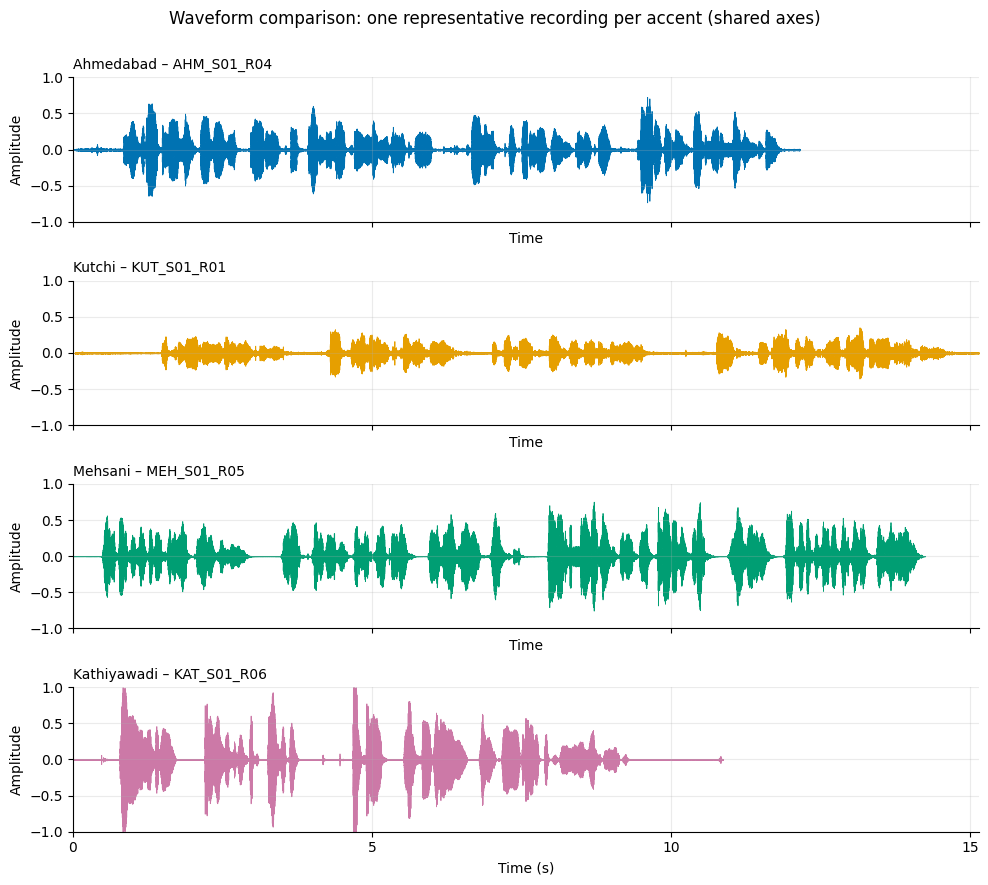

In [6]:
for a in present:
    rid, y, sr = rep_audio(a)
    fig, ax = plt.subplots(figsize=(10, 2.8))
    librosa.display.waveshow(y, sr=sr, ax=ax, color=COLORS[a], linewidth=0.6)
    ax.set_ylim(-1, 1); ax.set_xlim(0, len(y) / sr)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Amplitude (full scale = 1)")
    ax.set_title(f"Waveform – {a} – {rid}")
    save(fig, f"03_waveform_{a}_{rid}.png"); plt.show()

fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.2 * len(present)), sharex=True, sharey=True)
t_max = 0
for ax, a in zip(axes, present):
    rid, y, sr = rep_audio(a)
    librosa.display.waveshow(y, sr=sr, ax=ax, color=COLORS[a], linewidth=0.6)
    ax.set_ylim(-1, 1); ax.set_ylabel("Amplitude"); ax.set_title(f"{a} – {rid}", loc="left", fontsize=10)
    t_max = max(t_max, len(y) / sr)
axes[-1].set_xlim(0, t_max); axes[-1].set_xlabel("Time (s)")
fig.suptitle("Waveform comparison: one representative recording per accent (shared axes)", y=1.0)
fig.tight_layout(); save(fig, "04_waveform_comparison.png"); plt.show()

**How to read it:** bursts are syllables/words and flat stretches are pauses or silence. Large differences between panels in overall height (loudness/gain) or in how flat the gaps are (background noise) mostly reflect the recording setup and the speaker's speaking style, not necessarily accent.

## 5. Section C – STFT spectrograms
A spectrogram shows how energy is distributed over **frequency (y-axis)** as **time (x-axis)** evolves; colour is magnitude in dB. It is computed with a 32 ms Hamming-windowed STFT (`n_fft=512`, hop 128) and shown up to 8 kHz (the Nyquist limit at 16 kHz). Colour is in dB relative to the single loudest STFT bin across the four representative recordings, with a fixed −80…0 dB range for every panel, so brightness is comparable between figures.

What to look for: horizontal bands in voiced speech are harmonics of the pitch; broad dark/bright blobs are formants; vertical streaks are bursts (stops); noise-like energy at high frequencies is fricatives (e.g. "s", "sh"); dark gaps are pauses.

saved: results/audio_analysis/05_spectrogram_Ahmedabad_AHM_S01_R04.png


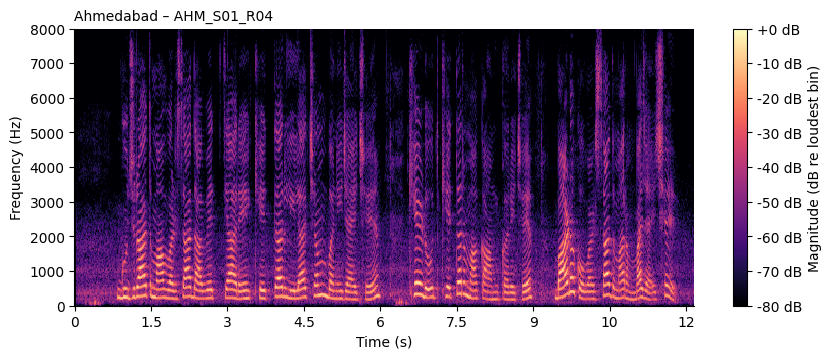

saved: results/audio_analysis/05_spectrogram_Kutchi_KUT_S01_R01.png


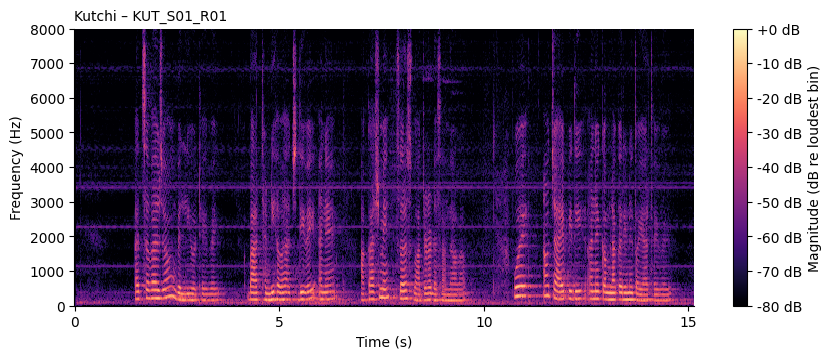

saved: results/audio_analysis/05_spectrogram_Mehsani_MEH_S01_R05.png


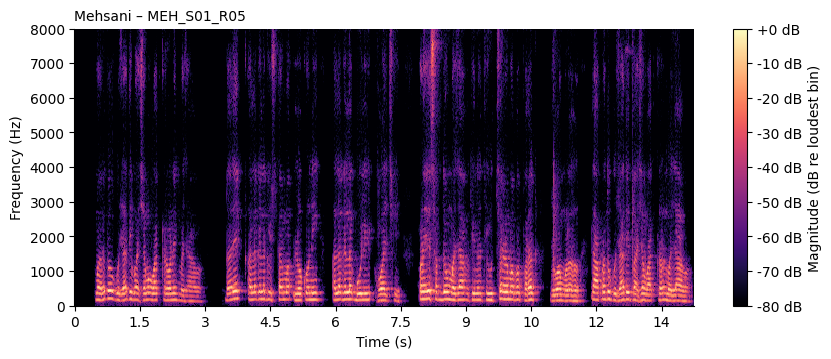

saved: results/audio_analysis/05_spectrogram_Kathiyawadi_KAT_S01_R06.png


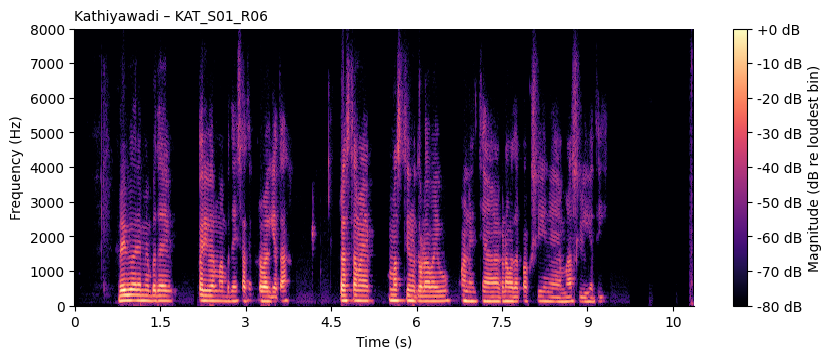

saved: results/audio_analysis/06_spectrogram_comparison.png


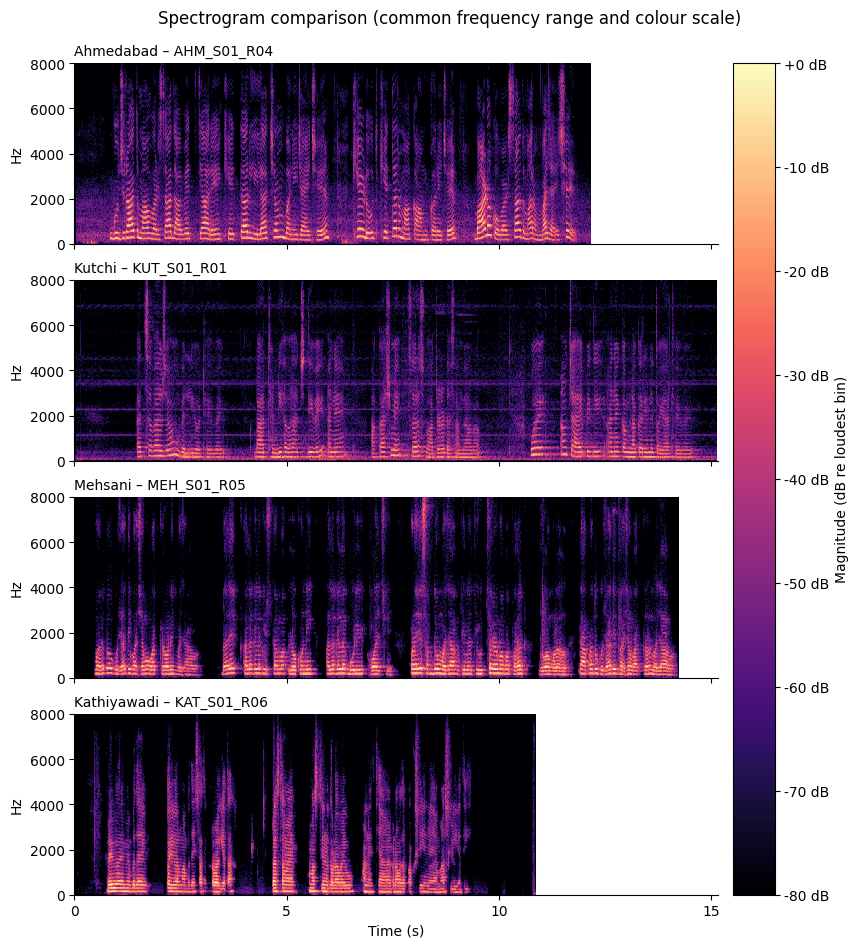

In [7]:
N_FFT, HOP, DB_RANGE = 512, 128, 80
stfts = {}
for a in present:
    rid, y, sr = rep_audio(a)
    stfts[a] = (rid, np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)), sr)
global_ref = max(S.max() for _, S, _ in stfts.values())

def draw_spec(ax, a):
    rid, S, sr = stfts[a]
    db = np.clip(librosa.amplitude_to_db(S, ref=global_ref, amin=1e-10, top_db=None), -DB_RANGE, 0)
    img = librosa.display.specshow(db, sr=sr, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax,
                                   vmin=-DB_RANGE, vmax=0, cmap="magma")
    ax.set_ylim(0, 8000); ax.set_title(f"{a} – {rid}", loc="left", fontsize=10); ax.grid(False)
    return img

for a in present:
    fig, ax = plt.subplots(figsize=(10, 3.6))
    img = draw_spec(ax, a)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Frequency (Hz)")
    fig.colorbar(img, ax=ax, format="%+d dB", label="Magnitude (dB re loudest bin)")
    save(fig, f"05_spectrogram_{a}_{stfts[a][0]}.png"); plt.show()

fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.7 * len(present)), sharex=True)
t_max = max(S.shape[1] * HOP / sr for _, S, sr in stfts.values())
for ax, a in zip(axes, present):
    img = draw_spec(ax, a); ax.set_xlabel(""); ax.set_ylabel("Hz")
axes[-1].set_xlim(0, t_max); axes[-1].set_xlabel("Time (s)")
fig.colorbar(img, ax=axes, format="%+d dB", label="Magnitude (dB re loudest bin)", pad=0.02)
fig.suptitle("Spectrogram comparison (common frequency range and colour scale)", y=0.93)
save(fig, "06_spectrogram_comparison.png"); plt.show()

**Observations (descriptive).** All four recordings show the expected speech structure (harmonic banding, formant regions, fricative noise above ~4 kHz, pauses between phrases). Differences in the background shade between pauses (how dark the gaps are), in high-frequency content, and in the overall brightness are the most visible. These can arise from the microphone, the codec the file went through before collection, the room, and the speaker's voice, as much as from accent. Fine accent-related cues (vowel quality, rhythm, intonation) cannot be judged by eye from a single recording each and are left to the later feature phases, where the same caveat about one speaker per accent applies.

## 6. Section D – Silence and speech activity
The figure shows frame energy (dB) for each representative recording, with the detected speech-level frames shaded, the two thresholds, and the quiet band in between. Nothing is cut from the audio.

saved: results/audio_analysis/07_speech_activity_timelines.png


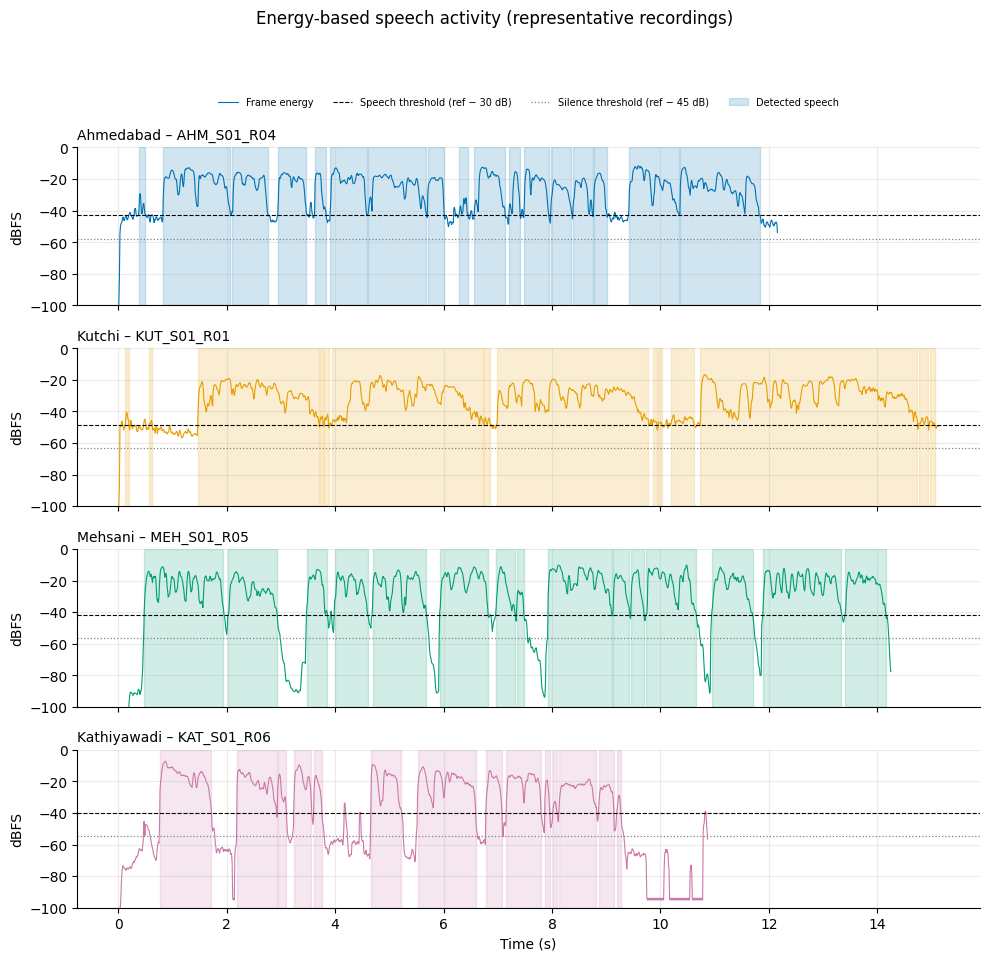

In [8]:
fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.3 * len(present)), sharex=True, sharey=True)
for ax, a in zip(axes, present):
    rid = REP[a]["recording_id"]; act = activities[rid]
    t = np.arange(len(act["frame_db"])) * act["frame_s"]
    ax.plot(t, act["frame_db"], color=COLORS[a], lw=0.8, label="Frame energy")
    ax.axhline(act["ref_db"] - aa.SPEECH_DB_BELOW_REF, color="k", ls="--", lw=0.8, label="Speech threshold (ref − 30 dB)")
    ax.axhline(act["ref_db"] - aa.SILENCE_DB_BELOW_REF, color="grey", ls=":", lw=0.9, label="Silence threshold (ref − 45 dB)")
    ax.fill_between(t, -100, 0, where=act["speech_mask"], color=COLORS[a], alpha=0.18, label="Detected speech")
    ax.set_ylim(-100, 0); ax.set_ylabel("dBFS"); ax.set_title(f"{a} – {rid}", loc="left", fontsize=10)
axes[0].legend(ncol=4, fontsize=7, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.2))
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Energy-based speech activity (representative recordings)", y=1.04)
fig.tight_layout(); save(fig, "07_speech_activity_timelines.png"); plt.show()

,leading_silence_s,trailing_silence_s,n_internal_pauses,internal_pause_total_s,longest_pause_s,speech_ratio,low_energy_frame_pct,quiet_frame_pct,silence_frame_pct
accent,,,,,,,,,
Ahmedabad,0.22,0.32,4.43,2.06,0.57,0.77,23.18,19.63,0.22
Kutchi,0.53,1.24,2.86,1.87,1.09,0.73,26.54,24.95,0.20
Mehsani,0.68,0.08,5.71,2.77,0.74,0.73,27.40,6.14,20.99
Kathiyawadi,0.75,1.47,3.14,1.69,0.84,0.61,38.76,8.20,30.29


saved: results/audio_analysis/08_silence_pause_summary.png


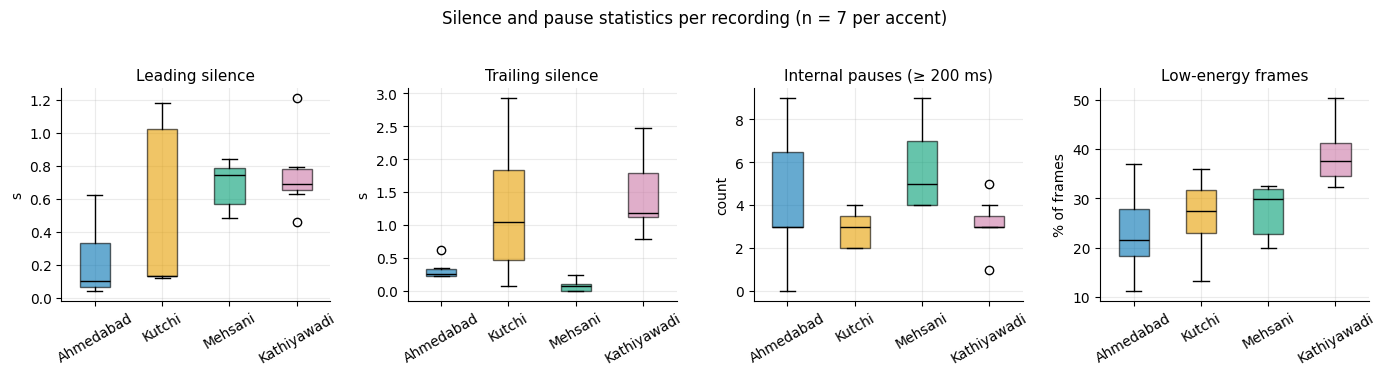

In [9]:
act_cols = ["leading_silence_s", "trailing_silence_s", "n_internal_pauses", "internal_pause_total_s",
            "longest_pause_s", "speech_ratio", "low_energy_frame_pct", "quiet_frame_pct", "silence_frame_pct"]
activity_summary = analysis.groupby("accent")[act_cols].mean().reindex(present).round(2)
display(activity_summary)
activity_summary.to_csv(OUT / "speech_activity_summary_by_accent.csv")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (col, title, unit) in zip(axes, [("leading_silence_s", "Leading silence", "s"),
        ("trailing_silence_s", "Trailing silence", "s"), ("n_internal_pauses", "Internal pauses (≥ 200 ms)", "count"),
        ("low_energy_frame_pct", "Low-energy frames", "% of frames")]):
    bp = ax.boxplot([analysis.loc[analysis.accent == a, col] for a in present], tick_labels=present,
                    patch_artist=True, medianprops={"color": "black"})
    for patch, a in zip(bp["boxes"], present):
        patch.set_facecolor(COLORS[a]); patch.set_alpha(0.6)
    ax.set_title(title); ax.set_ylabel(unit); ax.tick_params(axis="x", rotation=30)
fig.suptitle("Silence and pause statistics per recording (n = 7 per accent)", y=1.03)
fig.tight_layout(); save(fig, "08_silence_pause_summary.png"); plt.show()

**Reading this:** the speakers differ clearly in how long they wait before starting and after finishing (a recording-habit effect: when they pressed record/stop), and in how many pauses they take. Those pauses depend on sentence wording and delivery, so they should not be read as an accent trait. Because leading/trailing silence is not removed, remember it is part of what any later model will see.

## 7. Section E – Audio quality checks
Checks and thresholds (defined at the top of `src/audio_analysis.py`):

| Check | Flag when |
|---|---|
| Clipping | any sample at ≥ 0.999 of full scale |
| Low amplitude | peak < −20 dBFS or speech-level RMS < −35 dBFS |
| Empty / nearly silent | speech-level frames < 10 % or overall RMS < −60 dBFS |
| Unusual duration | < 0.5× or > 2× the median duration of all recordings |
| Inconsistent level | speech RMS more than 6 dB from the all-recording median |

Noise-floor level (10th-percentile frame energy) is also reported. Note it is **not comparable between M4A- and OGG-sourced files if their codecs gate silence differently** – see the results.

In [10]:
flag_cols = [c for c in analysis.columns if c.startswith("flag_")]
quality = analysis[["recording_id", "accent", "original_format", "duration_s", "peak_dbfs", "speech_rms_dbfs",
                    "overall_rms_dbfs", "noise_floor_dbfs", "clipped_sample_pct", "dc_offset", "level_dev_db",
                    "quality_flags"]].round(3)
display(quality)

flag_table = analysis.groupby("accent")[flag_cols].sum().reindex(present)
flag_table["recordings"] = analysis.groupby("accent").size().reindex(present)
display(flag_table)
by_accent = analysis.groupby("accent")[["peak_dbfs", "speech_rms_dbfs", "noise_floor_dbfs", "approx_snr_db"]].agg(["min", "mean", "max"]).reindex(present).round(1)
display(by_accent)
flag_table.to_csv(OUT / "quality_flag_counts_by_accent.csv")
by_accent.to_csv(OUT / "level_summary_by_accent.csv")

flagged = analysis[analysis["quality_flags"] != ""][["recording_id", "accent", "quality_flags"]]
lines = ["Phase 2 audio quality summary", "=" * 30, f"Recordings analysed: {len(analysis)}",
         f"Recordings with at least one flag: {len(flagged)}", ""]
for f in flag_cols:
    lines.append(f"{f[5:]:<20}: {int(analysis[f].sum())}  {list(analysis.loc[analysis[f], 'recording_id'])}")
(OUT / "quality_summary.txt").write_text(chr(10).join(lines) + chr(10), encoding="utf-8")
print(chr(10).join(lines))

,recording_id,accent,original_format,duration_s,peak_dbfs,speech_rms_dbfs,overall_rms_dbfs,noise_floor_dbfs,clipped_sample_pct,dc_offset,level_dev_db,quality_flags
0,AHM_S01_R01,Ahmedabad,M4A,14.187,-2.214,-19.365,-21.359,-45.443,0.000,-0.000,0.077,
1,AHM_S01_R02,Ahmedabad,M4A,11.968,-5.594,-21.419,-21.932,-45.002,0.000,0.000,-1.976,
2,AHM_S01_R03,Ahmedabad,M4A,11.989,-5.782,-21.571,-22.359,-45.304,0.000,-0.000,-2.128,
3,AHM_S01_R04,Ahmedabad,M4A,12.160,-2.746,-19.519,-20.490,-44.961,0.000,-0.000,-0.077,
4,AHM_S01_R05,Ahmedabad,M4A,17.259,-4.394,-20.539,-22.020,-47.440,0.000,0.000,-1.097,
5,AHM_S01_R06,Ahmedabad,M4A,12.117,-5.858,-21.600,-22.643,-45.632,0.000,0.000,-2.157,
6,AHM_S01_R07,Ahmedabad,M4A,16.448,-3.206,-21.130,-22.458,-46.531,0.000,0.000,-1.688,
7,KUT_S01_R01,Kutchi,M4A,15.147,-9.017,-25.475,-26.089,-49.092,0.000,0.000,-6.033,level_inconsistent
8,KUT_S01_R02,Kutchi,M4A,16.960,-6.514,-22.943,-24.331,-50.666,0.000,0.000,-3.501,
9,KUT_S01_R03,Kutchi,M4A,15.403,-1.956,-19.570,-20.549,-46.115,0.000,0.000,-0.128,


,flag_clipping,flag_low_amplitude,flag_near_silent,flag_unusual_duration,flag_level_inconsistent,recordings
accent,,,,,,
Ahmedabad,0,0,0,0,0,7
Kutchi,0,0,0,0,1,7
Mehsani,4,0,0,0,0,7
Kathiyawadi,6,0,0,0,0,7


peak_dbfs           speech_rms_dbfs             noise_floor_dbfs             approx_snr_db            
                  min mean  max             min  mean   max              min  mean   max           min  mean   max
accent                                                                                                            
Ahmedabad        -5.9 -4.3 -2.2           -21.6 -20.7 -19.4            -47.4 -45.8 -45.0          21.7  23.2  24.8
Kutchi           -9.0 -4.9 -2.0           -25.5 -21.8 -19.6            -50.8 -49.2 -46.1          20.1  24.2  29.6
Mehsani          -2.5 -0.4  0.0           -18.3 -17.0 -15.4            -93.1 -82.5 -66.9          47.3  63.3  72.9
Kathiyawadi      -1.9 -0.3  0.0           -19.7 -18.6 -17.1            -94.0 -79.7 -68.9          48.3  59.1  74.0

Phase 2 audio quality summary
Recordings analysed: 28
Recordings with at least one flag: 11

clipping            : 10  ['MEH_S01_R01', 'MEH_S01_R03', 'MEH_S01_R06', 'MEH_S01_R07', 'KAT_S01_R03', 'KAT_S01_R01', 'KAT_S01_R04', 'KAT_S01_R05', 'KAT_S01_R06', 'KAT_S01_R07']
low_amplitude       : 0  []
near_silent         : 0  []
unusual_duration    : 0  []
level_inconsistent  : 1  ['KUT_S01_R01']


saved: results/audio_analysis/09_quality_summary.png


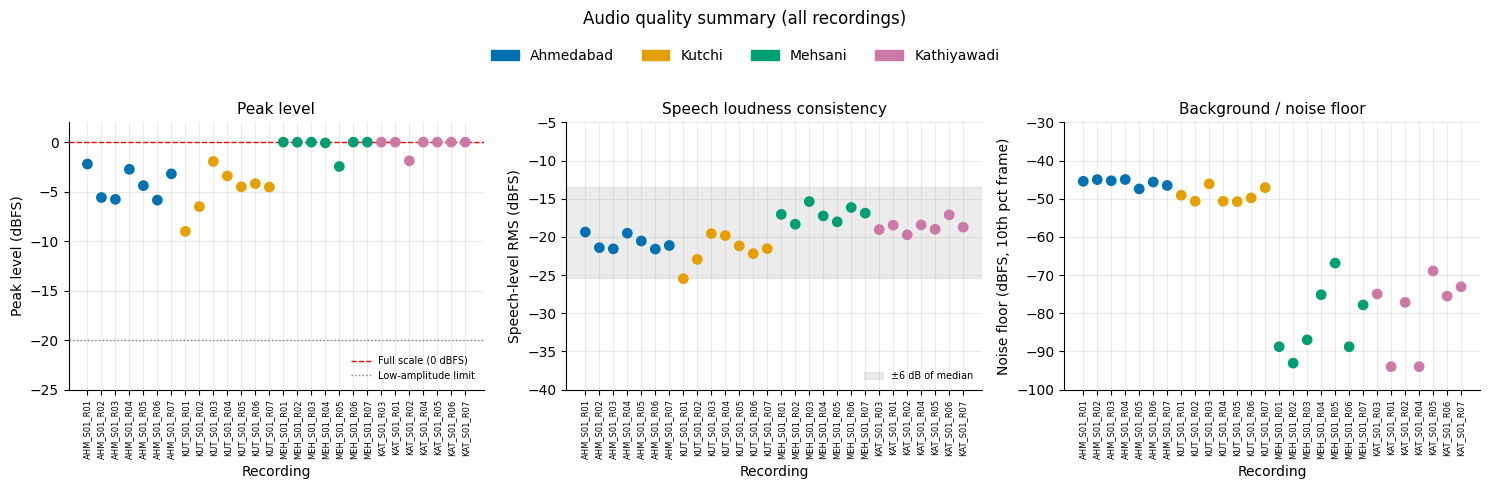

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
x = np.arange(len(analysis)); colors = [COLORS[a] for a in analysis["accent"]]
axes[0].scatter(x, analysis["peak_dbfs"], color=colors, s=45, zorder=3)
axes[0].axhline(0, color="red", ls="--", lw=1, label="Full scale (0 dBFS)")
axes[0].axhline(aa.LOW_PEAK_DBFS, color="grey", ls=":", lw=1, label="Low-amplitude limit")
axes[0].set_ylim(-25, 2); axes[0].set_ylabel("Peak level (dBFS)"); axes[0].set_title("Peak level"); axes[0].legend(fontsize=7, frameon=False, loc="lower right")
med = analysis["speech_rms_dbfs"].median()
axes[1].scatter(x, analysis["speech_rms_dbfs"], color=colors, s=45, zorder=3)
axes[1].axhspan(med - aa.LEVEL_DEVIATION_DB, med + aa.LEVEL_DEVIATION_DB, color="grey", alpha=0.15, label="±6 dB of median")
axes[1].set_ylim(-40, -5); axes[1].set_ylabel("Speech-level RMS (dBFS)"); axes[1].set_title("Speech loudness consistency"); axes[1].legend(fontsize=7, frameon=False, loc="lower right")
axes[2].scatter(x, analysis["noise_floor_dbfs"], color=colors, s=45, zorder=3); axes[2].set_ylim(-100, -30)
axes[2].set_ylabel("Noise floor (dBFS, 10th pct frame)"); axes[2].set_title("Background / noise floor")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(analysis["recording_id"], rotation=90, fontsize=6); ax.set_xlabel("Recording")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[a]) for a in present]
fig.legend(handles, present, ncol=len(present), loc="upper center", bbox_to_anchor=(0.5, 1.04), frameon=False)
fig.suptitle("Audio quality summary (all recordings)", y=1.1)
fig.tight_layout(); save(fig, "09_quality_summary.png"); plt.show()

In [12]:
# Is the recording chain confounded with accent? (original container vs noise floor)
display(analysis.groupby(["original_format", "accent"])["noise_floor_dbfs"].agg(["count", "min", "median", "max"]).round(1))

count   min  median   max
original_format accent                                
M4A             Ahmedabad        7 -47.4   -45.4 -45.0
                Kutchi           7 -50.8   -49.8 -46.1
OGG             Kathiyawadi      7 -94.0   -75.5 -68.9
                Mehsani          7 -93.1   -87.0 -66.9

## 8. What the results suggest, and what they cannot show
**Observations**

- **Format and recording integrity.** All 28 files meet the 16 kHz / mono / PCM_16 spec and have positive durations; no metadata is missing apart from the intentionally empty `recording_type`.
- **Durations** are about 9.6–18.3 s per file (Kathiyawadi is shortest on average, Kutchi longest) (see the duration tables). Differences between accents are of similar size to the spread within an accent, and sentence wording differs between speakers, so duration is not informative about accent here. No recording is extreme enough to be flagged as an unusual duration.
- **Silence and pauses.** Speakers differ in leading/trailing silence and pause counts. Mehsani files tend to end almost immediately after the last word, while Kutchi and Kathiyawadi files often carry one to three seconds of trailing silence. Ahmedabad shows short leading/trailing silence but several internal pauses in the longer sentences.
- **Recording chain.** The Ahmedabad and Kutchi (M4A) files have a noise floor of roughly −45 to −51 dBFS, i.e. audible room/device noise between words. The Mehsani and Kathiyawadi (OGG) files have a far lower floor (roughly −67 to −94 dBFS), consistent with digital silence/noise gating applied before or during encoding. Their peaks are also at or near full scale, and several files contain full-scale samples (flagged as clipping, usually a handful of samples). The "approx. SNR" column is therefore **not comparable** across the two groups.
- **Tonal interference.** The Kutchi spectrogram shows steady horizontal lines (around 1.1, 2.3, 3.4 and 4.5 kHz) running through pauses, i.e. a constant hum/electronic tone in that recording chain. It is absent from the representative recordings of the other accents.
- **Level consistency.** Speech loudness is within a few dB for most files; a Kutchi file (KUT_S01_R01) is several dB quieter than the rest, but none is low enough to be flagged as too quiet or near-silent.

**Issues needing attention**
1. **Accent is perfectly confounded with recording chain.** The two M4A accents and the two OGG accents differ in noise floor and loudness profile. A classifier could learn the codec/device/noise-gating signature instead of the accent. Mitigations for later phases: record all accents with the same device/app and format if possible, add more speakers per accent, and avoid over-interpreting early classification scores.
2. **Clipping** in some Mehsani and Kathiyawadi recordings (see the flag table). Check whether it came from the original OGG or from decoding; if the originals can be re-recorded at lower gain, prefer that. It was not corrected here.
3. **Variable leading/trailing silence** (up to a few seconds in some files). Trimming or handling this is a Phase 3 decision, not applied here.
4. **Surti** must be recorded with the same device and settings as the others, ideally matching whichever chain the rest of the data will standardise on.

**What cannot be concluded**
- Nothing here characterises "the Ahmedabad / Kutchi / Mehsani / Kathiyawadi accent" in general: each class is one speaker, so speaker voice, device, room, codec and chosen vocabulary are inseparable from accent.
- No differences are claimed to be statistically significant, and no tests were run.
- The energy-based activity measure cannot perfectly separate quiet speech from low-level noise.

Phase 2 ends here. MFCC extraction and model training have not been started.